In [14]:
import os
import time
import copy
import random
import sys

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [15]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [17]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [18]:
def find_project_root():
    current = Path.cwd().resolve()

    while current != current.parent:
        if (current / ".git").exists():
            return current

        current = current.parent

    raise FileNotFoundError("Could not find project root.")


PROJECT_ROOT = find_project_root()

DATA_ROOT = PROJECT_ROOT / "data" / "gtsrb"
SPLIT_DIR = PROJECT_ROOT / "splits"
RESULTS_DIR = PROJECT_ROOT / "results"

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\Jaindu Samaranayaka\Documents\Semester_5\PR\CNN for image classification


In [19]:
if str(PROJECT_ROOT) not in sys.path:

    sys.path.insert(
        0,
        str(PROJECT_ROOT)
    )

In [20]:
from Common.dataset import create_dataloaders

from Common.models import (
    ModelB,
    count_parameters
)

from Common.training import train_model

In [21]:
train_df = pd.read_csv(
    SPLIT_DIR / "train_split.csv"
)

val_df = pd.read_csv(
    SPLIT_DIR / "val_split.csv"
)

test_df = pd.read_csv(
    SPLIT_DIR / "test_split.csv"
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 18648
Validation: 3996
Test: 3996


In [22]:
train_loader, val_loader, test_loader = create_dataloaders(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    data_root=DATA_ROOT,
    batch_size=32,
    num_workers=0
)

## Model B: Depthwise-Separable CNN

Model B keeps Model A's four-block topology and `3 -> 16 -> 32 -> 32 -> 32` channel progression. Each `3 x 3` convolution is replaced by a depthwise `3 x 3` convolution followed by a pointwise `1 x 1` convolution, then ReLU and `2 x 2` max pooling. The resulting `32 x 4 x 4` feature map feeds the same `Linear(512, 43)` classifier as Model A. ReLU avoids exponential activations, and depthwise filtering reduces multiply-accumulate work while keeping the comparison controlled.

At `64 x 64` input, Model A has **45,643** trainable parameters and about **9,459,200 MACs** per image. Model B has **25,526** trainable parameters and about **1,420,800 MACs** per image (approximately **85% fewer MACs**). Model B is below the 100,000 parameter limit.


In [23]:
model_b = ModelB().to(device)

print(model_b)

parameters_b = count_parameters(
    model_b
)

print(
    "Model B trainable parameters:",
    parameters_b
)

ModelB(
  (features): Sequential(
    (0): DepthwiseSeparableConv(
      (depthwise): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=3, bias=False)
      (pointwise): Conv2d(3, 16, kernel_size=(1, 1), stride=(1, 1))
      (relu): ReLU()
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): DepthwiseSeparableConv(
      (depthwise): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
      (pointwise): Conv2d(16, 32, kernel_size=(1, 1), stride=(1, 1))
      (relu): ReLU()
    )
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): DepthwiseSeparableConv(
      (depthwise): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
      (pointwise): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1))
      (relu): ReLU()
    )
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6)

Forward-pass smoke check

In [24]:
images, labels = next(iter(train_loader))
model_b.eval()
with torch.inference_mode():
    logits = model_b(images.to(device))
assert logits.shape == (images.shape[0], 43)
assert torch.isfinite(logits).all()
print(f"Smoke check passed: {tuple(images.shape)} -> {tuple(logits.shape)}")


Smoke check passed: (32, 3, 64, 64) -> (32, 43)


In [25]:
from Common.training import (
    train_model,
    create_optimizer
)

from Common.evaluation import (
    get_predictions,
    calculate_metrics,
    plot_training_curves,
    plot_confusion_matrix,
    print_classification_report,
    total_parameters,
    estimated_fp32_size_kb,
    save_model_and_get_size,
    measure_inference_time
)

In [26]:
selected_optimizer = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "selected_optimizer.txt"
).read_text().strip()

print(
    "Final optimizer:",
    selected_optimizer
)

Final optimizer: Adam


In [27]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


model_b = ModelB().to(
    device
)

criterion = nn.CrossEntropyLoss()

optimizer_b = create_optimizer(
    selected_optimizer,
    model_b.parameters()
)

In [28]:
model_b, history_b = train_model(
    model=model_b,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b,
    criterion=criterion,
    epochs=30,
    device=device
)

Epoch 01/30 | Train Loss: 2.8215 | Train Acc: 0.2089 | Val Loss: 1.7759 | Val Acc: 0.4525 | Time: 36.75s
Epoch 02/30 | Train Loss: 1.6323 | Train Acc: 0.4833 | Val Loss: 1.2287 | Val Acc: 0.5911 | Time: 36.31s
Epoch 03/30 | Train Loss: 1.2048 | Train Acc: 0.6055 | Val Loss: 0.8532 | Val Acc: 0.7242 | Time: 45.34s
Epoch 04/30 | Train Loss: 0.9079 | Train Acc: 0.7052 | Val Loss: 0.6430 | Val Acc: 0.7793 | Time: 44.48s
Epoch 05/30 | Train Loss: 0.7137 | Train Acc: 0.7681 | Val Loss: 0.4845 | Val Acc: 0.8318 | Time: 33.40s
Epoch 06/30 | Train Loss: 0.5606 | Train Acc: 0.8155 | Val Loss: 0.3962 | Val Acc: 0.8689 | Time: 33.75s
Epoch 07/30 | Train Loss: 0.4832 | Train Acc: 0.8437 | Val Loss: 0.3540 | Val Acc: 0.8781 | Time: 33.01s
Epoch 08/30 | Train Loss: 0.4267 | Train Acc: 0.8605 | Val Loss: 0.3080 | Val Acc: 0.8999 | Time: 33.06s
Epoch 09/30 | Train Loss: 0.3771 | Train Acc: 0.8751 | Val Loss: 0.2512 | Val Acc: 0.9157 | Time: 32.92s
Epoch 10/30 | Train Loss: 0.3307 | Train Acc: 0.8894 | 

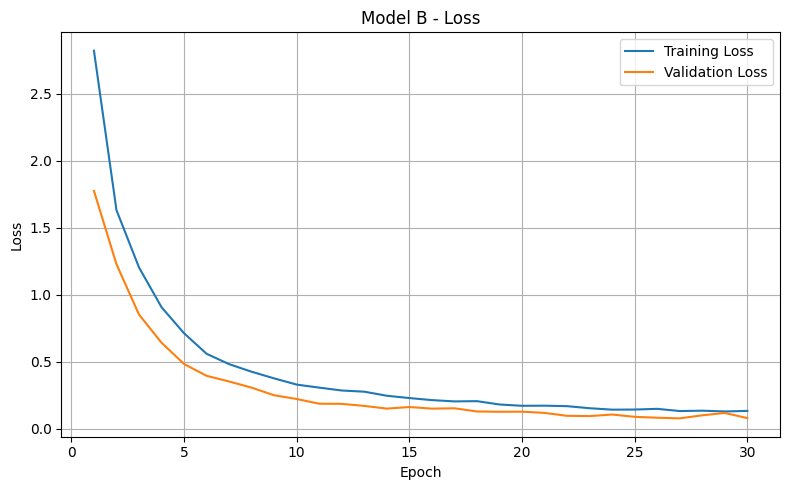

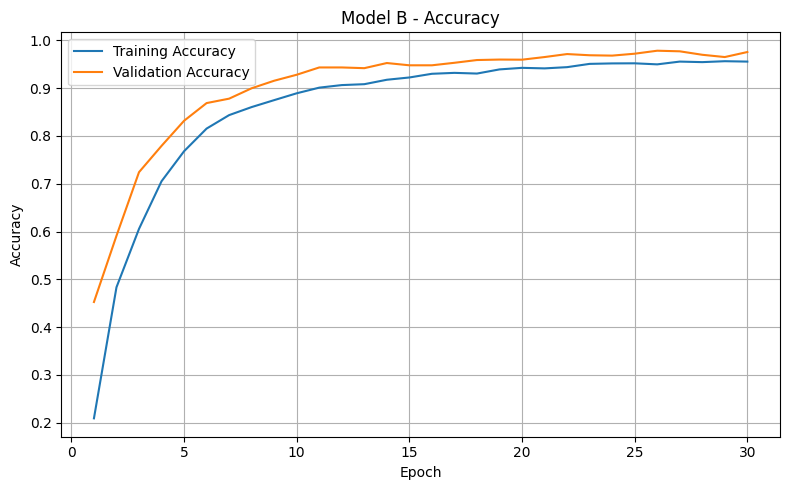

In [29]:
FIGURES_DIR = (
    PROJECT_ROOT
    / "results"
    / "figures"
)

plot_training_curves(
    history=history_b,
    model_name="Model B",
    save_dir=FIGURES_DIR
)

In [30]:
y_true_b, y_pred_b = get_predictions(
    model_b,
    test_loader,
    device
)

metrics_b = calculate_metrics(
    y_true_b,
    y_pred_b
)

print(metrics_b)

{'Test Accuracy': 0.9767267267267268, 'Macro Precision': 0.9806833554287041, 'Macro Recall': 0.9790990022944088}


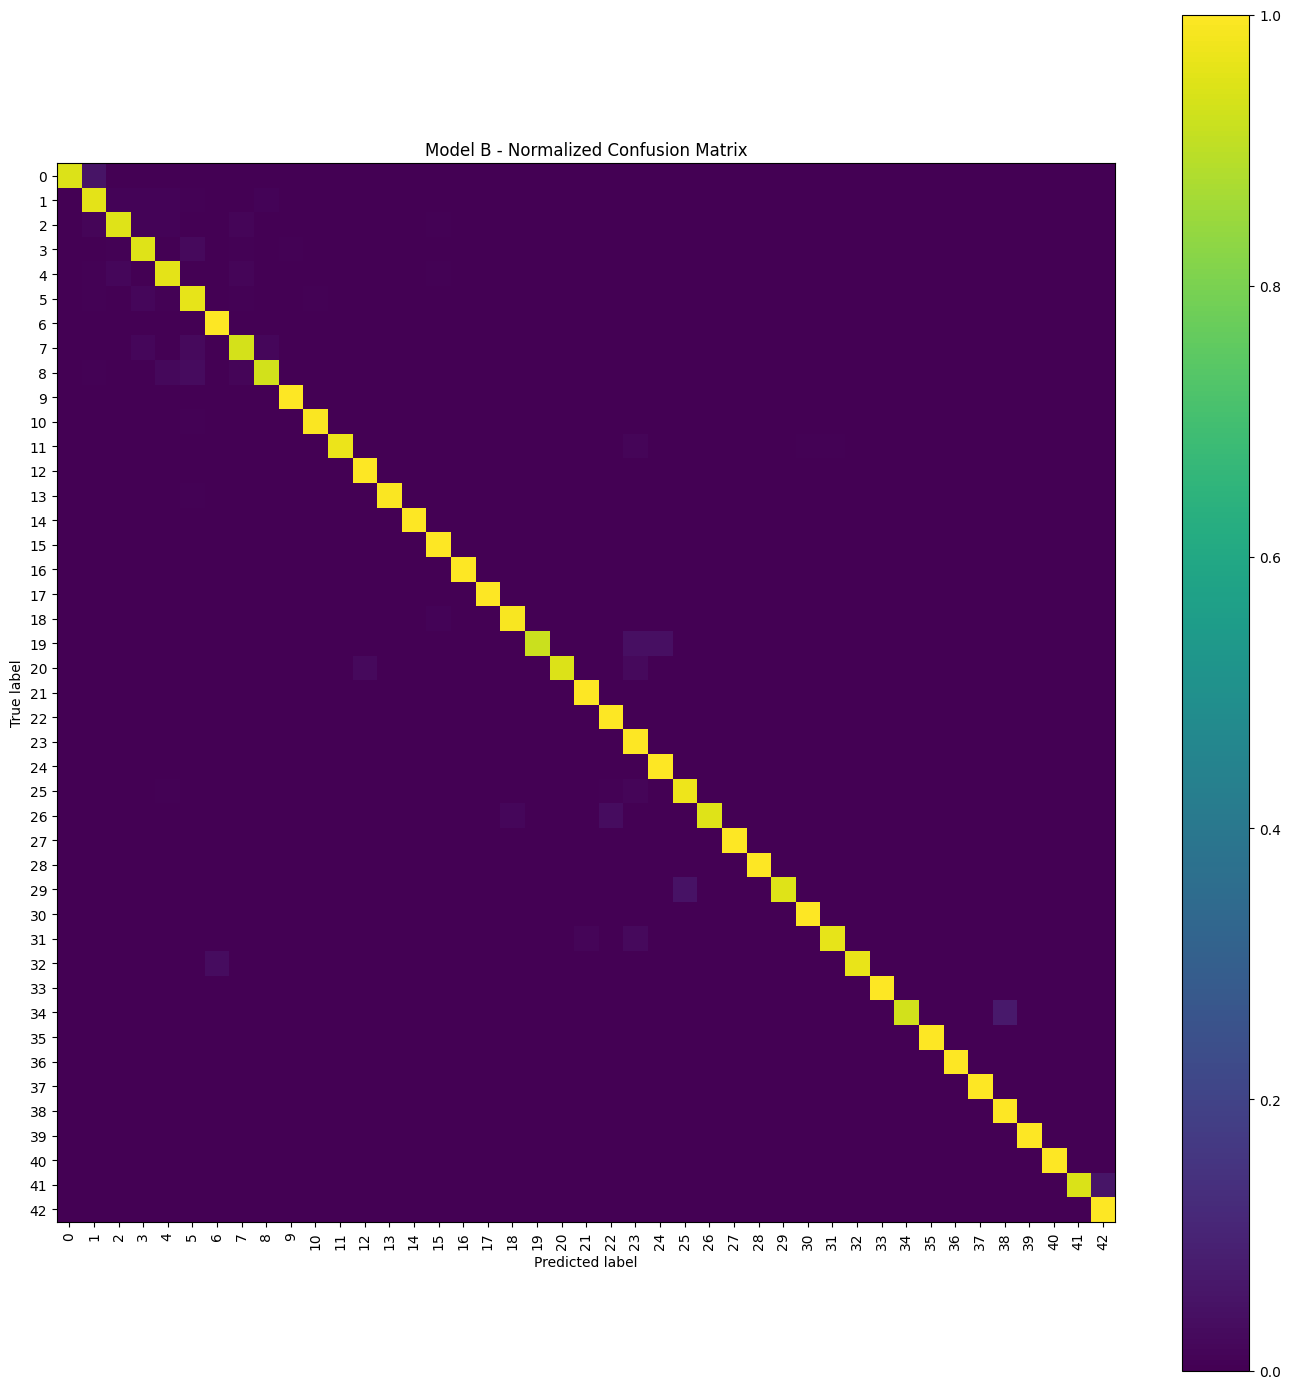

In [31]:
plot_confusion_matrix(
    y_true_b,
    y_pred_b,
    model_name="Model B",
    save_dir=FIGURES_DIR
)

In [32]:
print_classification_report(
    y_true_b,
    y_pred_b
)

              precision    recall  f1-score   support

           0     1.0000    0.9474    0.9730        19
           1     0.9683    0.9596    0.9640       223
           2     0.9694    0.9528    0.9610       233
           3     0.9276    0.9527    0.9400       148
           4     0.9593    0.9593    0.9593       221
           5     0.9306    0.9617    0.9459       209
           6     0.9792    1.0000    0.9895        47
           7     0.9355    0.9355    0.9355       155
           8     0.9640    0.9306    0.9470       144
           9     0.9936    1.0000    0.9968       155
          10     0.9949    0.9949    0.9949       197
          11     1.0000    0.9712    0.9854       139
          12     0.9953    1.0000    0.9977       213
          13     1.0000    0.9953    0.9976       213
          14     1.0000    1.0000    1.0000        78
          15     0.9647    1.0000    0.9820        82
          16     1.0000    1.0000    1.0000        34
          17     1.0000    

In [33]:
average_epoch_time_b = np.mean(
    history_b["epoch_time"]
)

print(
    "Average epoch time:",
    average_epoch_time_b
)

Average epoch time: 34.1760440500002


In [34]:
parameters_b = total_parameters(
    model_b
)

estimated_size_b = (
    estimated_fp32_size_kb(
        model_b
    )
)

model_b_path = (
    PROJECT_ROOT
    / "checkpoints"
    / "model_b_final.pth"
)

actual_size_b = (
    save_model_and_get_size(
        model_b,
        model_b_path
    )
)

print(
    "Parameters:",
    parameters_b
)

print(
    "Estimated size:",
    estimated_size_b,
    "KB"
)

print(
    "Actual size:",
    actual_size_b,
    "KB"
)

Parameters: 25526
Estimated size: 99.7109375 KB
Actual size: 105.6103515625 KB


In [35]:
inference_time_b = (
    measure_inference_time(
        model_b,
        test_loader,
        device
    )
)

print(
    "Inference time:",
    inference_time_b,
    "ms/image"
)

Inference time: 0.341721562500652 ms/image


In [36]:
(PROJECT_ROOT / "results" / "metrics").mkdir(parents=True, exist_ok=True)

model_b_results = {
    "Model": "Model B",
    "Parameters": parameters_b,
    "Estimated FP32 Size (KB)": estimated_size_b,
    "Actual Model Size (KB)": actual_size_b,
    "Average Epoch Time (s)": average_epoch_time_b,
    "Inference Time (ms/image)": inference_time_b,
    "Test Accuracy": metrics_b["Test Accuracy"],
    "Macro Precision": metrics_b["Macro Precision"],
    "Macro Recall": metrics_b["Macro Recall"]
}

model_b_df = pd.DataFrame(
    [model_b_results]
)

model_b_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "model_b_metrics.csv",
    index=False
)

model_b_df

,Model,Parameters,Estimated FP32 Size (KB),Actual Model Size (KB),Average Epoch Time (s),Inference Time (ms/image),Test Accuracy,Macro Precision,Macro Recall
0,Model B,25526,99.710938,105.610352,34.176044,0.341722,0.976727,0.980683,0.979099
